# Initial EDA — Manufacturing Measurements

Understand the CSV, identify quality concerns, and find patterns to investigate next.

**Start here:** This notebook points to the included **synthetic example CSV**, not your production data. Keep the example CSV beside the notebook, or change `CSV_PATH` below. Choose **Restart Kernel → Run All** after changing settings.

**Eight steps:** setup → inspect → quality checks → numeric exploration → categories → relationships and time → unusual records → findings.

This is an initial exploration. It flags issues without deleting records, filling missing measurements, calculating specification pass/fail, or ranking vendors.

**Part II** follows Section 8 and performs the recommended follow-up investigations, including a separate exact-copy sensitivity scenario.


## 1. Objective and setup

**Purpose:** Select the CSV. The notebook automatically discovers and summarizes all feature/part/unit combinations. No feature or part filter is required.

`MAX_PLOT_GROUPS` limits optional per-group charts. `PLOT_GROUP_IDS` can select groups from the current Section 4 inventory; leaving it empty plots the largest complete groups first. Set `PLOT_COMBINATIONS=False` to skip those charts. None of these settings limit the tables.

If packages are missing, run `%pip install pandas numpy matplotlib seaborn` in a separate cell once. This notebook expects pandas 2 or later.

**Question to answer:** What does one row represent—one measurement, one inspection, or a repeated inspection? Record your answer in Section 8.


In [1]:
# Purpose: Set the file path and optional chart limits. All combinations are summarized.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

CSV_PATH = Path("example_manufacturing_measurements.csv")
DATE_FORMAT = "%m/%d/%Y %H:%M"  # Screenshot format: month/day/year hour:minute.

pd.set_option("display.max_columns", 25)
sns.set_theme(style="whitegrid")
print("File:", CSV_PATH.resolve())
if CSV_PATH.name == "example_manufacturing_measurements.csv":
    print("SYNTHETIC EXAMPLE — these are not production measurements.")

# These settings limit only the per-group charts in Sections 4 and 6, not the tables.
PLOT_COMBINATIONS = True
MAX_PLOT_GROUPS = 3
PLOT_GROUP_IDS = []  # Optional: e.g. ["G001", "G003"] from the current Section 4 table.
TABLE_PREVIEW_ROWS = 20  # Full tables are retained and exported, even when the preview is shorter.
EXPORT_TABLES = True
SUMMARY_FOLDER = Path("initial_eda_summaries")

if not isinstance(MAX_PLOT_GROUPS, int) or MAX_PLOT_GROUPS < 0:
    raise ValueError("MAX_PLOT_GROUPS must be a nonnegative integer.")
if not isinstance(TABLE_PREVIEW_ROWS, int) or TABLE_PREVIEW_ROWS < 1:
    raise ValueError("TABLE_PREVIEW_ROWS must be a positive integer.")


File:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\example_manufacturing_measurements.csv

SYNTHETIC EXAMPLE — these are not production measurements.

## 2. Load and inspect the data

**Purpose:** See the size, columns, and first few records. All source columns initially load as text to preserve identifiers such as `000123`. Known measurement fields will be converted in the next section.

**Read the output:** The named `source_record` index is a one-based imported-record number. It remains useful after sorting; it is not necessarily a physical CSV line number.

The sample uses the screenshot's 20 column names and order. `type` and `is_pass_fail` are blank in the sample, as in the visible rows. `unit="Standard"` is preserved as a source label; this notebook does not infer inches or millimeters from it.


In [2]:
# Purpose: Load a source copy and a separate working copy without changing the CSV.
df_raw = pd.read_csv(CSV_PATH, dtype="string", keep_default_na=False, na_values=[""])
df_raw.index = pd.RangeIndex(1, len(df_raw) + 1, name="source_record")
df = df_raw.copy(deep=True)

expected_columns = [
    "feature_name", "actual", "nominal", "upper_tolerance", "lower_tolerance", "type",
    "deviation", "is_pass_fail", "feature_type", "unit", "part_number", "material_family",
    "size", "serial_no", "date", "work_order", "po_number", "vendor_id", "vendor_name", "commodity",
]
print("Expected columns absent:", [c for c in expected_columns if c not in df] or "None")
print("Additional columns:", [c for c in df if c not in expected_columns] or "None")

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print("Columns:", df.columns.tolist())
display(df.head())
display(df.dtypes.to_frame("loaded_type"))


Expected columns absent:

None

Additional columns:

None

Rows: 162 | Columns: 20

Columns:

['feature_name', 'actual', 'nominal', 'upper_tolerance', 'lower_tolerance', 'type', 'deviation', 'is_pass_fail', 'feature_type', 'unit', 'part_number', 'material_family', 'size', 'serial_no', 'date', 'work_order', 'po_number', 'vendor_id', 'vendor_name', 'commodity']

,feature_name,actual,nominal,upper_tolerance,lower_tolerance,type,deviation,is_pass_fail,feature_type,unit,part_number,material_family,size,serial_no,date,work_order,po_number,vendor_id,vendor_name,commodity
source_record,,,,,,,,,,,,,,,,,,,,
1,_090_1,0.0199135,0.02,0.003,0.003,<NA>,-0.0000865,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000000,1/1/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
2,_090_1,<NA>,0.02,0.003,0.003,<NA>,-0.0001037,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000001,1/4/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
3,_090_1,check source,0.02,0.003,0.003,<NA>,-0.0000668,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000002,1/7/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
4,_090_1,0.0204212,0.02,0.003,0.003,<NA>,0.0004212,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000003,invalid date,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS
5,_090_1,0.0199234,0.02,0.003,0.003,<NA>,-0.0000766,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000004,1/13/2026 14:27,DEMO-WO-900001-0,005000,900001,SYNTHETIC VENDOR A,MACHPARTS


,loaded_type
feature_name,string
actual,string
nominal,string
upper_tolerance,string
lower_tolerance,string
type,string
deviation,string
is_pass_fail,string
feature_type,string
unit,string


## 3. Basic data-quality checks

**Purpose:** Find missing values, parsing problems, duplicates, and possible repeated inspections.

The working copy trims surrounding spaces and converts recognized measurement/date columns. Invalid numeric values become missing **and are counted below**; the source copy retains their original text. No rows are deleted or missing measurements filled.

**Read the output:** Exact duplicates compare original source fields. Repeated measurement keys can be legitimate reinspection and should not automatically be removed. Missing percentages describe the working data after parsing.


In [3]:
# Purpose: Convert known measurements and dates while recording conversion problems.
for column in df.columns:
    df[column] = df[column].str.strip().replace("", pd.NA)

numeric_columns = [c for c in ["actual", "nominal", "deviation", "upper_tolerance", "lower_tolerance"] if c in df]
conversion_rows = []
for column in numeric_columns:
    original = df[column]
    converted = pd.to_numeric(original, errors="coerce").astype(float)
    invalid = original.notna() & (converted.isna() | ~np.isfinite(converted))
    conversion_rows.append({"column": column, "missing_before": int(original.isna().sum()),
                            "invalid_values": int(invalid.sum())})
    df[column] = converted.replace([np.inf, -np.inf], np.nan)

if "date" in df:
    original_date = df["date"].copy()
    # Update DATE_FORMAT in Section 1 if your actual file uses a different date format.
    df["date"] = pd.to_datetime(original_date, errors="coerce", format=DATE_FORMAT)
    conversion_rows.append({"column": "date", "missing_before": int(original_date.isna().sum()),
                            "invalid_values": int((original_date.notna() & df.date.isna()).sum())})
display(pd.DataFrame(conversion_rows, columns=["column", "missing_before", "invalid_values"]))


,column,missing_before,invalid_values
0,actual,1,1
1,nominal,0,0
2,deviation,0,0
3,upper_tolerance,0,0
4,lower_tolerance,0,0
5,date,0,1


,type,missing_count,missing_percent,unique_values,examples
is_pass_fail,string,162,100.0,0,[]
type,string,162,100.0,0,[]
actual,float64,2,1.2,158,"[0.0199135, 0.0204212, 0.0199234]"
date,datetime64[us],1,0.6,40,"[2026-01-01 14:27:00, 2026-01-04 14:27:00, 202..."
upper_tolerance,float64,0,0.0,2,"[0.003, 0.01]"
nominal,float64,0,0.0,2,"[0.02, 0.0]"
feature_name,string,0,0.0,2,"[_090_1, Key 040 .010 Profile Total_5]"
lower_tolerance,float64,0,0.0,2,"[0.003, 0.0]"
feature_type,string,0,0.0,2,"[Inner Diameter, Profile]"
unit,string,0,0.0,1,[Standard]


Examples show up to three distinct values, not every value.

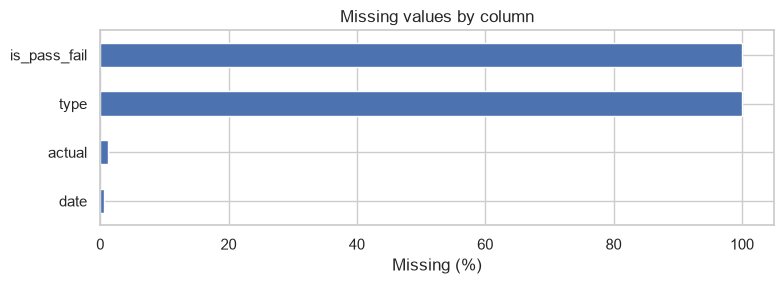

In [4]:
# Purpose: Show missingness, distinct values, and a few examples for each column.
profile = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(1),
    "unique_values": df.nunique(dropna=True),
    "examples": [df[c].dropna().astype(str).unique()[:3].tolist() for c in df],
}).sort_values("missing_percent", ascending=False)
display(profile)
print("Examples show up to three distinct values, not every value.")

missing = profile.loc[profile.missing_count > 0, "missing_percent"].sort_values()
if not missing.empty:
    missing.plot.barh(figsize=(8, max(3, len(missing) * 0.35)))
    plt.xlabel("Missing (%)"); plt.title("Missing values by column")
    plt.tight_layout(); plt.show()


In [5]:
# Purpose: Flag duplication and simple tolerance issues without removing records.
exact_extra = df_raw.duplicated(keep="first")
exact_members = df_raw.duplicated(keep=False)
print("Exact duplicate copies beyond the first:", int(exact_extra.sum()))
display(df_raw.loc[exact_members].head(12))

measurement_key = ["serial_no", "part_number", "feature_name", "date"]
if set(measurement_key).issubset(df.columns):
    measurement_key += [c for c in ["vendor_id", "work_order"] if c in df]
    complete_key = df[measurement_key].notna().all(axis=1)
    repeated = complete_key & df.duplicated(measurement_key, keep=False)
    print("Rows in repeated complete-key groups:", int(repeated.sum()))
    print("Rows with incomplete candidate keys:", int((~complete_key).sum()))
    review_columns = measurement_key + [c for c in ["actual"] if c in df]
    display(df.loc[repeated, review_columns].sort_values(measurement_key).head(12))

for column in [c for c in ["lower_tolerance", "upper_tolerance"] if c in df]:
    print(f"Negative values in {column}: {int(df[column].lt(0).sum())} — confirm source conventions.")


Exact duplicate copies beyond the first:

2

,feature_name,actual,nominal,upper_tolerance,lower_tolerance,type,deviation,is_pass_fail,feature_type,unit,part_number,material_family,size,serial_no,date,work_order,po_number,vendor_id,vendor_name,commodity
source_record,,,,,,,,,,,,,,,,,,,,
13,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000012,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS
59,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000018,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS
161,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000012,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS
162,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000018,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS


Rows in repeated complete-key groups:

4

Rows with incomplete candidate keys:

1

,serial_no,part_number,feature_name,date,vendor_id,work_order,actual
source_record,,,,,,,
13,000012,4A1534,_090_1,2026-02-06 14:27:00,900001,DEMO-WO-900001-1,0.020394
161,000012,4A1534,_090_1,2026-02-06 14:27:00,900001,DEMO-WO-900001-1,0.020394
59,000018,4A1534,_090_1,2026-02-24 14:27:00,900002,DEMO-WO-900002-1,0.020503
162,000018,4A1534,_090_1,2026-02-24 14:27:00,900002,DEMO-WO-900002-1,0.020503


Negative values in lower_tolerance: 0 — confirm source conventions.

Negative values in upper_tolerance: 0 — confirm source conventions.

## 4. Numeric exploration

**Purpose:** Find every combination and summarize measurements within consistent contexts.

| Table | A row represents | What to look for |
|---|---|---|
| Combination inventory | One feature name + part number + unit | Record counts, usable/missing measurements, vendors, dates, and changing specifications |
| Group statistics | Above, plus feature type, material, size, nominal, upper tolerance, lower tolerance | Mean, median, standard deviation, minimum, maximum, and comparison status |

Vendor is not part of the measurement-group definition: vendors are compared **within** each group. Serial numbers, dates, work orders, and purchase orders remain traceability fields. They do not split every measurement into its own group.

Missing grouping fields remain visible in the inventory and group table. Measurement statistics and vendor comparisons are skipped for incomplete contexts, negative tolerance allowances, or groups with no usable actual measurements. A complete context does not prove engineering validity or establish a vendor effect.

**Read the output:** `specification_variants` counts distinct nominal/tolerance combinations, including incomplete ones. `specifications_vary=True` means one exploration group contains more than one such combination. `comparison_groups` also reflects material, size, and feature-type differences. The preview shows up to `TABLE_PREVIEW_ROWS` rows; Section 8 saves the full tables.


In [6]:
# Purpose: Discover all exploration groups and comparable contexts without dropping missing keys.
EXPLORATION_KEYS = ["feature_name", "part_number", "unit"]
SPEC_KEYS = ["nominal", "upper_tolerance", "lower_tolerance"]
COMPARISON_KEYS = EXPLORATION_KEYS + ["feature_type", "material_family", "size"] + SPEC_KEYS

group_data = df.copy()
# Missing columns get placeholders only in this analysis copy, so their absence stays visible.
for column in COMPARISON_KEYS + ["actual", "vendor_id", "date"]:
    if column not in group_data:
        group_data[column] = pd.NaT if column == "date" else np.nan if column in SPEC_KEYS + ["actual"] else pd.NA
if not pd.api.types.is_datetime64_any_dtype(group_data.date):
    print("Group date coverage unavailable: review the parsed date field.")
    group_data["date"] = pd.NaT

group_data["group_id"] = (group_data.groupby(COMPARISON_KEYS, dropna=False, sort=True).ngroup()
                          .map(lambda number: f"G{int(number)+1:03d}"))
group_data["specification_id"] = group_data.groupby(SPEC_KEYS, dropna=False, sort=True).ngroup()
group_data["context_missing"] = group_data[COMPARISON_KEYS].isna().any(axis=1)
group_lookup = group_data[["group_id"] + COMPARISON_KEYS].drop_duplicates()

combination_inventory = group_data.groupby(EXPLORATION_KEYS, dropna=False).agg(
    records=("actual", "size"), usable_measurements=("actual", "count"),
    vendors=("vendor_id", "nunique"), first_date=("date", "min"), last_date=("date", "max"),
    specification_variants=("specification_id", "nunique"), comparison_groups=("group_id", "nunique"),
    rows_missing_context=("context_missing", "sum"),
).reset_index()
combination_inventory["missing_measurements"] = combination_inventory.records-combination_inventory.usable_measurements
combination_inventory["specifications_vary"] = combination_inventory.specification_variants > 1

group_summary = group_data.groupby("group_id").agg(
    records=("actual", "size"), usable_measurements=("actual", "count"), vendors=("vendor_id", "nunique"),
    mean=("actual", "mean"), median=("actual", "median"), std=("actual", "std"),
    minimum=("actual", "min"), maximum=("actual", "max"),
).reset_index().merge(group_lookup, on="group_id", how="left", validate="one_to_one")
group_summary["missing_measurements"] = group_summary.records-group_summary.usable_measurements
group_summary["missing_context_fields"] = group_summary[COMPARISON_KEYS].apply(
    lambda row: ", ".join(row.index[row.isna()]), axis=1) if len(group_summary) else pd.Series(dtype="string")
group_summary["status"] = np.select(
    [group_summary.missing_context_fields.ne(""),
     (group_summary.upper_tolerance < 0) | (group_summary.lower_tolerance < 0),
     group_summary.usable_measurements.eq(0)],
    ["review missing context", "review negative tolerance", "no usable measurements"], default="descriptive summary available")
group_summary["comparison_ready"] = group_summary.status.eq("descriptive summary available")
stats_columns = ["mean", "median", "std", "minimum", "maximum"]
group_summary.loc[~group_summary.comparison_ready, stats_columns] = np.nan
group_summary = group_summary[["group_id"]+COMPARISON_KEYS+[
    "records", "usable_measurements", "missing_measurements", "vendors"]+stats_columns+[
    "missing_context_fields", "status", "comparison_ready"]]

print(f"Exploration combinations: {len(combination_inventory):,}; measurement groups: {len(group_summary):,}")
print(f"Inventory covers {combination_inventory.records.sum():,} of {len(df):,} input rows, including duplicates.")
display(combination_inventory.head(TABLE_PREVIEW_ROWS))
display(group_summary.head(TABLE_PREVIEW_ROWS))
print("These are previews. The full tables are saved in Section 8 when EXPORT_TABLES=True.")


Exploration combinations: 2; measurement groups: 2

Inventory covers 162 of 162 input rows, including duplicates.

,feature_name,part_number,unit,records,usable_measurements,vendors,first_date,last_date,specification_variants,comparison_groups,rows_missing_context,missing_measurements,specifications_vary
0,Key 040 .010 Profile Total_5,4A1206,Standard,80,80,2,2026-01-01 14:27:00,2026-04-28 14:27:00,1,1,0,0,False
1,_090_1,4A1534,Standard,82,80,2,2026-01-01 14:27:00,2026-04-28 14:27:00,1,1,0,2,False


,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,records,usable_measurements,missing_measurements,vendors,mean,median,std,minimum,maximum,missing_context_fields,status,comparison_ready
0,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,80,80,0,2,0.004257,0.004229,0.000890,0.002319,0.006466,,descriptive summary available,True
1,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,82,80,2,2,0.020200,0.020153,0.000704,0.018428,0.024200,,descriptive summary available,True


These are previews. The full tables are saved in Section 8 when EXPORT_TABLES=True.

Groups selected for charts:

['G002', 'G001']

Group IDs identify this run's contexts; recheck them if you change the input data.

Chart context:

,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
source_record,,,,,,,,,,
1,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003


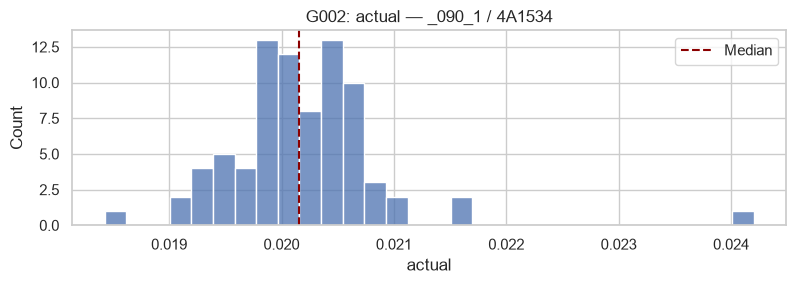

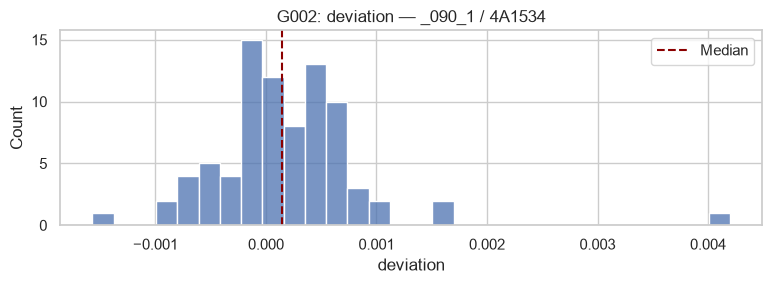

Chart context:

,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
source_record,,,,,,,,,,
81,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.0,0.01,0.0


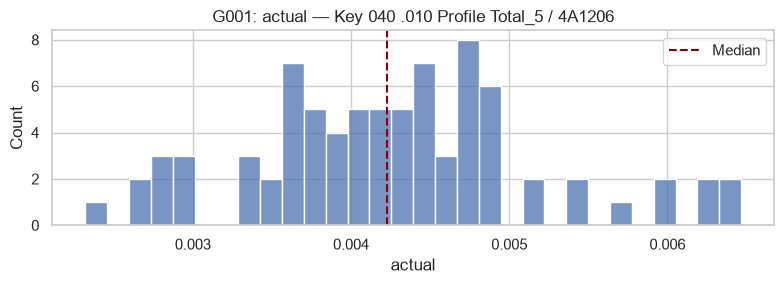

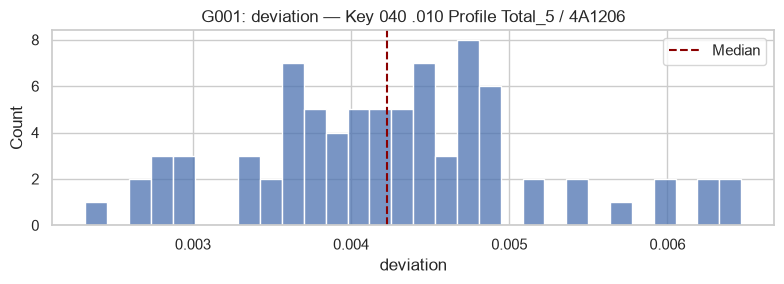

In [7]:
# Purpose: Plot a limited number of complete groups while retaining every group in the tables.
available_groups = group_summary.loc[group_summary.comparison_ready].sort_values(
    ["records", "group_id"], ascending=[False, True])
requested_ids = list(dict.fromkeys(PLOT_GROUP_IDS))
if requested_ids:
    plot_ids = [gid for gid in requested_ids if gid in set(available_groups.group_id)]
    print("Requested groups unavailable for plots:", [gid for gid in requested_ids if gid not in plot_ids] or "None")
else:
    plot_ids = available_groups.group_id.tolist()
plot_ids = plot_ids[:MAX_PLOT_GROUPS] if PLOT_COMBINATIONS else []
print("Groups selected for charts:", plot_ids or "None")
print("Group IDs identify this run's contexts; recheck them if you change the input data.")

for gid in plot_ids:
    current = group_data.loc[group_data.group_id.eq(gid)]
    print("Chart context:")
    display(group_lookup.loc[group_lookup.group_id.eq(gid)])
    for column in [c for c in ["actual", "deviation"] if c in current]:
        values = current[column].dropna()
        if not values.empty:
            plt.figure(figsize=(8, 3))
            sns.histplot(values, bins=30)
            plt.axvline(values.median(), color="darkred", linestyle="--", label="Median")
            plt.title(f"{gid}: {column} — {current.feature_name.iloc[0]} / {current.part_number.iloc[0]}")
            plt.legend(); plt.tight_layout(); plt.show()
            plt.close()


## 5. Categorical exploration

**Purpose:** See which vendors, features, parts, materials, and sizes are most common. Counts describe inspection records, not necessarily unique parts or production volume.

**Read the output:** Check dominant groups, rare labels, and missing categories. Tables and plots show at most 10 categories each; all values remain in the data. If a source pass/fail field exists, its labels are counted without validating them or calculating new outcomes.


,vendor_id,vendor_name
source_record,,
1,900001,SYNTHETIC VENDOR A
41,900002,SYNTHETIC VENDOR B


vendor_id: 2 distinct nonmissing values

,rows,percent
vendor_id,,
900001,81,50.0
900002,81,50.0


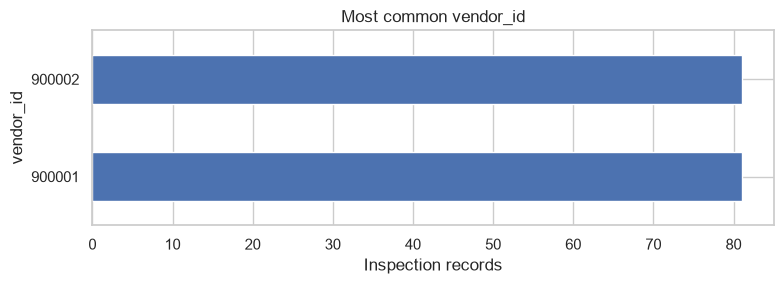

feature_type: 2 distinct nonmissing values

,rows,percent
feature_type,,
Inner Diameter,82,50.6
Profile,80,49.4


feature_name: 2 distinct nonmissing values

,rows,percent
feature_name,,
_090_1,82,50.6
Key 040 .010 Profile Total_5,80,49.4


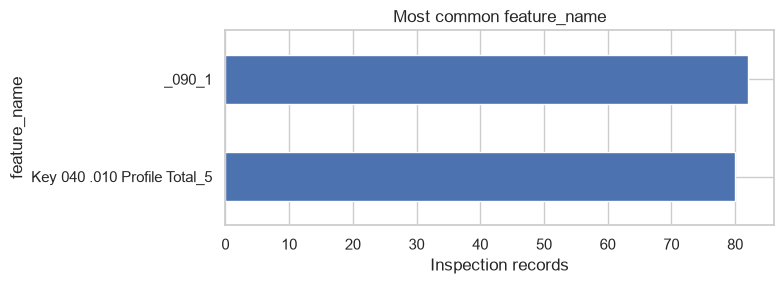

part_number: 2 distinct nonmissing values

,rows,percent
part_number,,
4A1534,82,50.6
4A1206,80,49.4


material_family: 1 distinct nonmissing values

,rows,percent
material_family,,
Steel,162,100.0


size: 2 distinct nonmissing values

,rows,percent
size,,
Micro,82,50.6
Small,80,49.4


... (2 outputs left out)

commodity: 1 distinct nonmissing values

,rows,percent
commodity,,
MACHPARTS,162,100.0


is_pass_fail: 0 distinct nonmissing values

,rows,percent
is_pass_fail,,
<MISSING>,162,100.0


In [8]:
# Purpose: Summarize category frequencies using vendor IDs when available.
vendor_column = "vendor_id" if "vendor_id" in df else "vendor_name"
if set(["vendor_id", "vendor_name"]).issubset(df.columns):
    display(df[["vendor_id", "vendor_name"]].drop_duplicates().head(20))
category_columns = [c for c in [vendor_column, "feature_type", "feature_name", "part_number",
                               "material_family", "size", "type", "commodity", "is_pass_fail"] if c in df]
for column in category_columns:
    counts = df[column].fillna("<MISSING>").value_counts(dropna=False)
    summary = counts.rename("rows").to_frame()
    summary["percent"] = (counts / len(df) * 100).round(1) if len(df) else np.nan
    print(f"{column}: {df[column].nunique()} distinct nonmissing values")
    display(summary.head(10))
    if column in [vendor_column, "feature_name"] and not counts.empty:
        counts.head(10).sort_values().plot.barh(figsize=(8, 3))
        plt.xlabel("Inspection records"); plt.title(f"Most common {column}")
        plt.tight_layout(); plt.show()


## 6. Basic relationships and time coverage

**Purpose:** Summarize every complete group by vendor. Each row of the vendor table is one vendor within one measurement group. Group IDs link back to Section 4's exact context.

The table covers all complete groups, including groups with only one vendor. Box plots use only the optional chart selection from Section 4 and require at least two vendors with usable measurements. Missing vendor IDs remain visible in the table as missing; they are excluded from vendor plots.

**Read the output:** Box plots show median, spread, and unusual points. They do not establish which vendor is better. Duplicate records and repeated inspections remain included. A group can have a valid descriptive summary without enough independent evidence for a vendor conclusion.

The time chart uses the entire CSV and shows inspection activity and gaps. It is not a process-control chart. Confirm date formats and timezone conventions before interpreting timing.


Vendor/group rows summarized: 4

,group_id,vendor_id,records,usable_measurements,mean,median,std,minimum,maximum,missing_measurements,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
0,G001,900001,40,40,0.004048,0.004142,0.000836,0.002319,0.006020,0,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
1,G001,900002,40,40,0.004467,0.004448,0.000902,0.002717,0.006466,0,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
2,G002,900001,41,39,0.020080,0.020070,0.000845,0.018428,0.024200,2,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003
3,G002,900002,41,41,0.020313,0.020352,0.000523,0.019334,0.021601,0,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003


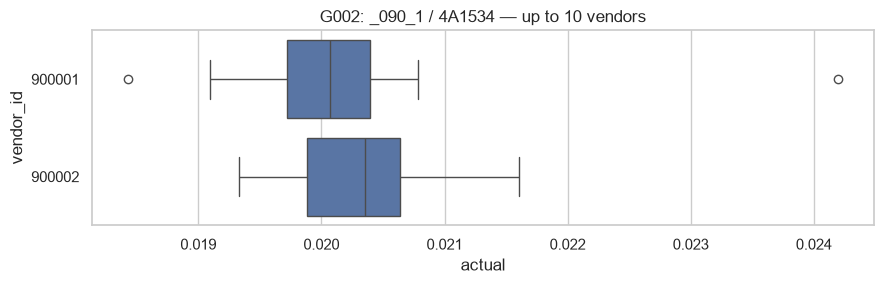

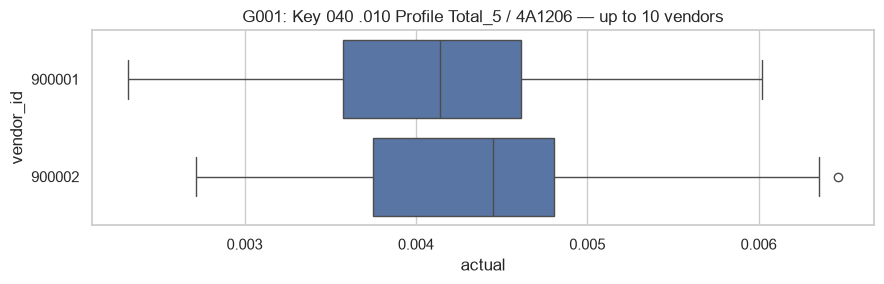

In [9]:
# Purpose: Summarize all complete groups by vendor, then plot only the selected groups.
ready_ids = set(group_summary.loc[group_summary.comparison_ready, "group_id"])
comparable_data = group_data.loc[group_data.group_id.isin(ready_ids)].copy()
vendor_summary = comparable_data.groupby(["group_id", "vendor_id"], dropna=False).agg(
    records=("actual", "size"), usable_measurements=("actual", "count"),
    mean=("actual", "mean"), median=("actual", "median"), std=("actual", "std"),
    minimum=("actual", "min"), maximum=("actual", "max"),
).reset_index()
vendor_summary["missing_measurements"] = vendor_summary.records-vendor_summary.usable_measurements
vendor_summary = vendor_summary.merge(group_lookup, on="group_id", how="left", validate="many_to_one")
print(f"Vendor/group rows summarized: {len(vendor_summary):,}")
display(vendor_summary.head(TABLE_PREVIEW_ROWS))

for gid in plot_ids:
    current = comparable_data.loc[comparable_data.group_id.eq(gid)].dropna(subset=["actual", "vendor_id"])
    if current.vendor_id.nunique() < 2:
        print(f"{gid}: vendor chart skipped; fewer than two vendors with usable measurements.")
        continue
    top_vendors = current.vendor_id.value_counts().head(10).index
    plot_data = current.loc[current.vendor_id.isin(top_vendors)]
    plt.figure(figsize=(9, max(3, len(top_vendors)*.45)))
    sns.boxplot(data=plot_data, x="actual", y="vendor_id", showfliers=True)
    plt.title(f"{gid}: {current.feature_name.iloc[0]} / {current.part_number.iloc[0]} — up to 10 vendors")
    plt.tight_layout(); plt.show()
    plt.close()


Date range:

2026-01-01 14:27:00

to

2026-04-28 14:27:00

Records without a valid date:

1

,inspection_records
date,
2026-01-01,43
2026-02-01,38
2026-03-01,40
2026-04-01,40


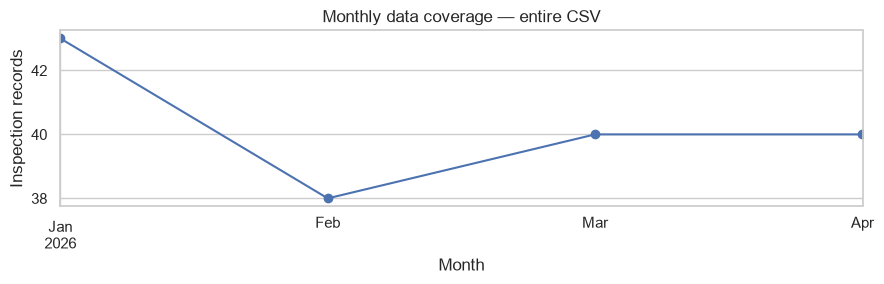

In [10]:
# Purpose: Show the date range and monthly inspection counts, including empty months.
monthly_counts = pd.Series(dtype="int64", name="inspection_records")
if "date" in df and pd.api.types.is_datetime64_any_dtype(df["date"]):
    dated = df.dropna(subset=["date"])
    if not dated.empty:
        print("Date range:", dated.date.min(), "to", dated.date.max())
        print("Records without a valid date:", int(df.date.isna().sum()))
        monthly_counts = dated.set_index("date").resample("MS").size().rename("inspection_records")
        display(monthly_counts.to_frame())
        monthly_counts.plot(figsize=(9, 3), marker="o")
        plt.ylabel("Inspection records"); plt.xlabel("Month")
        plt.title("Monthly data coverage — entire CSV")
        plt.tight_layout(); plt.show()
    else:
        print("No valid dates available.")
else:
    print("Time chart skipped: no usable date field; review its format/timezone if present.")


## 7. Unusual-record review

**Purpose:** Review the five smallest and five largest usable actual measurements **within every complete measurement group**, including groups not chosen for charts.

This is an investigation list, not an automatic outlier classification or specification-failure test. A record can be among a small group's extremes without being unusual. Groups with fewer than ten usable records may contribute all their records.

**Read the output:** `group_id` links to the context in Section 4; `source_record` and the available vendor, serial, date, work-order, and purchase-order fields trace the observation. No records are deleted. The notebook previews a limited number of rows and Section 8 exports the full review list.


In [11]:
# Purpose: Collect traceable low/high records from every complete group, independently of chart limits.
extreme_parts = []
for gid, current in comparable_data.dropna(subset=["actual"]).groupby("group_id"):
    extremes = pd.concat([current.nsmallest(5, "actual"), current.nlargest(5, "actual")])
    extremes = extremes.loc[~extremes.index.duplicated()].sort_values("actual")
    extreme_parts.append(extremes)
extremes = pd.concat(extreme_parts) if extreme_parts else comparable_data.iloc[:0].copy()
review_columns = ["group_id"]+COMPARISON_KEYS+["actual", "deviation", "vendor_id", "vendor_name",
                    "serial_no", "work_order", "po_number", "date"]
review_columns = list(dict.fromkeys(c for c in review_columns if c in extremes))
extreme_records = extremes[review_columns]
print(f"Extreme-record review: {len(extreme_records):,} records from {extreme_records.group_id.nunique():,} groups.")
display(extreme_records.head(TABLE_PREVIEW_ROWS))


Extreme-record review: 20 records from 2 groups.

,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,actual,deviation,vendor_id,vendor_name,serial_no,work_order,po_number,date
source_record,,,,,,,,,,,,,,,,,,
107,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002319,0.002319,900001,SYNTHETIC VENDOR A,000026,DEMO-WO-900001-2,005002,2026-03-20 14:27:00
105,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002697,0.002697,900001,SYNTHETIC VENDOR A,000024,DEMO-WO-900001-2,005002,2026-03-14 14:27:00
131,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002717,0.002717,900002,SYNTHETIC VENDOR B,000010,DEMO-WO-900002-1,005001,2026-01-31 14:27:00
101,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002759,0.002759,900001,SYNTHETIC VENDOR A,000020,DEMO-WO-900001-2,005002,2026-03-02 14:27:00
102,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.002790,0.002790,900001,SYNTHETIC VENDOR A,000021,DEMO-WO-900001-2,005002,2026-03-05 14:27:00
112,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006020,0.006020,900001,SYNTHETIC VENDOR A,000031,DEMO-WO-900001-3,005003,2026-04-04 14:27:00
145,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006202,0.006202,900002,SYNTHETIC VENDOR B,000024,DEMO-WO-900002-2,005002,2026-03-14 14:27:00
155,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006326,0.006326,900002,SYNTHETIC VENDOR B,000034,DEMO-WO-900002-3,005003,2026-04-13 14:27:00
122,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006353,0.006353,900002,SYNTHETIC VENDOR B,000001,DEMO-WO-900002-0,005000,2026-01-04 14:27:00


## 8. Initial findings and next steps

**Purpose:** Record the main observations and save the complete tables. Chart and preview limits do not limit exported data.

1. **Scope:** The file contains ___ rows, ___ exploration combinations, and ___ measurement groups. One row represents ___.
2. **Data quality:** Missing values, parsing issues, duplicates, or incomplete group definitions needing attention are ___.
3. **Coverage:** Most records come from ___. Groups with limited vendor coverage or changing specifications are ___.
4. **Measurements:** Groups ___ deserve investigation because their typical values, spread, or extremes show ___.
5. **Relationships:** Possible vendor or time patterns are ___. These are provisional because ___.
6. **Next steps:** Confirm ___ with the data owner, investigate source records ___, and then consider ___ for deeper analysis.

The export cell saves `combination_inventory.csv`, `group_statistics.csv`, `vendor_group_statistics.csv`, and `extreme_records.csv` in `SUMMARY_FOLDER`. Incomplete groups remain in the first two files with their status. These summary files are refreshed on each run; the input CSV is never changed. IDs and record-review files should be stored with the same access restrictions as the input.

**Done for initial EDA:** You can describe the dataset, locate every measurement context, identify quality concerns, and choose questions for deeper analysis. No formal vendor ranking or statistical testing is performed here.


In [12]:
# Purpose: Save full tables so previews and chart limits do not hide combinations.
if EXPORT_TABLES:
    SUMMARY_FOLDER.mkdir(parents=True, exist_ok=True)
    full_tables = {"combination_inventory.csv": combination_inventory,
                   "group_statistics.csv": group_summary,
                   "vendor_group_statistics.csv": vendor_summary,
                   "extreme_records.csv": extreme_records.reset_index()}
    for filename, table in full_tables.items():
        target = SUMMARY_FOLDER / filename
        if target.resolve() == CSV_PATH.resolve():
            raise ValueError("Choose a summary folder that does not overwrite the input CSV.")
        table.to_csv(target, index=False)
    print("Full tables saved to:", SUMMARY_FOLDER.resolve())
else:
    print("Exports disabled. Full tables remain available as DataFrames in this notebook session.")


Full tables saved to:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\initial_eda_summaries

# Part II

**Basic follow-up checks**

Run Part I first, or choose **Restart Kernel → Run All**. This part uses the same `CSV_PATH` and keeps the source data and Part I results intact. The saved local example uses the synthetic CSV; select your Optimus export in Section 1 to analyze that file.

We investigate five questions using simple counts, grouped summaries, and one standard outlier rule. Keeping one copy of each exact source row is a comparison scenario, not proof that deleting those rows is an approved correction. Other repeated inspections may remain.

Only **four complete review tables** are exported: duplicate evidence, missing-context records, group before/after statistics, and flagged measurements. Other summaries stay inside the notebook. `TABLE_PREVIEW_ROWS` limits previews, not exported rows.


In [13]:
# Purpose: Prepare a separate analysis copy and one simple review setting.
MIN_REVIEW_RECORDS = 10  # A screening choice, not proof of statistical adequacy or independence.
PART_II_FOLDER = SUMMARY_FOLDER / "part_ii"
if not isinstance(MIN_REVIEW_RECORDS, int) or MIN_REVIEW_RECORDS < 2:
    raise ValueError("MIN_REVIEW_RECORDS must be an integer of at least 2.")
if not df_raw.index.equals(group_data.index) or not group_data.index.is_unique:
    raise ValueError("Restart and run Part I so the source and working records align.")

p2_data = group_data.copy()
p2_data["extra_exact_copy"] = df_raw.duplicated(keep="first")
p2_unique = p2_data.loc[~p2_data.extra_exact_copy].copy()
print("Input:", CSV_PATH.resolve())
print(f"Original rows: {len(p2_data):,}; keeping one exact copy: {len(p2_unique):,}.")


Input:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\example_manufacturing_measurements.csv

Original rows: 162; keeping one exact copy: 160.

## 1. Check duplicates by vendor, part, and month

**What we do:** Count extra exact source copies, show where they occur, and put matching records together in one evidence table. Matching uses every original source column. The evidence table includes all original columns so you can compare the copies directly.

**How to read it:** `first_source_record` links each set to its first occurrence. `copies_in_set` includes the original; `extra_exact_copy=True` identifies later copies. Each category's duplicate percentage uses its own record count as the denominator. Missing dates appear as a missing month category.

Repeated measurement keys were already checked in Part I. Here we focus only on exact copies. The source system or data owner must explain why they occur before you adopt a deletion rule. Only the complete matching-record evidence is exported; the breakdowns remain in the notebook.


In [14]:
# Purpose: Count exact copies and show their source records together.
p2_extra_n = int(p2_data.extra_exact_copy.sum())
print("Extra exact copies:", p2_extra_n)
print("Extra-copy percentage:", round(100 * p2_extra_n / len(p2_data), 2) if len(p2_data) else "N/A")
p2_data["year_month"] = p2_data.date.dt.to_period("M").astype("string")
for p2_column in ["vendor_id", "part_number", "year_month"]:
    p2_breakdown = p2_data.groupby(p2_column, dropna=False).agg(
        records=("actual", "size"), extra_copies=("extra_exact_copy", "sum")).reset_index()
    p2_breakdown["extra_copy_percent"] = 100 * p2_breakdown.extra_copies / p2_breakdown.records
    print("Duplicates by", p2_column)
    display(p2_breakdown.sort_values("extra_copies", ascending=False).head(TABLE_PREVIEW_ROWS))

p2_members = df_raw.loc[df_raw.duplicated(keep=False)]
p2_duplicate_evidence = p2_members.copy()
p2_duplicate_evidence.insert(0, "source_record", p2_members.index)
if not p2_members.empty:
    p2_duplicate_evidence["duplicate_set"] = p2_members.groupby(
        list(df_raw.columns), dropna=False, sort=False).ngroup().to_numpy() + 1
    p2_sets = p2_duplicate_evidence.groupby("duplicate_set")
    p2_duplicate_evidence["first_source_record"] = p2_sets.source_record.transform("min")
    p2_duplicate_evidence["copies_in_set"] = p2_sets.source_record.transform("size")
else:
    for p2_column in ["duplicate_set", "first_source_record", "copies_in_set"]:
        p2_duplicate_evidence[p2_column] = pd.Series(dtype="int64")
p2_duplicate_evidence["extra_exact_copy"] = p2_data.loc[p2_members.index, "extra_exact_copy"]
p2_duplicate_evidence = p2_duplicate_evidence.reset_index(drop=True).sort_values(["duplicate_set", "source_record"])
print("All members of exact-match sets:", len(p2_duplicate_evidence), "(preview below)")
display(p2_duplicate_evidence.head(TABLE_PREVIEW_ROWS))


Extra exact copies:

2

Extra-copy percentage:

1.23

Duplicates by

vendor_id

... (7 outputs left out)

All members of exact-match sets:

4

(preview below)

,source_record,feature_name,actual,nominal,upper_tolerance,lower_tolerance,type,deviation,is_pass_fail,feature_type,unit,part_number,material_family,size,serial_no,date,work_order,po_number,vendor_id,vendor_name,commodity,duplicate_set,first_source_record,copies_in_set,extra_exact_copy
0,13,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000012,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS,1,13,2,False
2,161,_090_1,0.020394,0.02,0.003,0.003,<NA>,0.000394,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000012,2/6/2026 14:27,DEMO-WO-900001-1,005001,900001,SYNTHETIC VENDOR A,MACHPARTS,1,13,2,True
1,59,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000018,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS,2,59,2,False
3,162,_090_1,0.0205034,0.02,0.003,0.003,<NA>,0.0005034,<NA>,Inner Diameter,Standard,4A1534,Steel,Micro,000018,2/24/2026 14:27,DEMO-WO-900002-1,005001,900002,SYNTHETIC VENDOR B,MACHPARTS,2,59,2,True


## 2. Check unit labels and missing measurement context

**What we do:** Count observed unit labels, count missing grouping fields, and list affected source records. We count records missing either unit or size once, even if both are missing.

**How to read it:** Missing fields explain why a measurement group cannot receive some summaries. A populated label such as Standard or Metric still needs a confirmed physical meaning. Ask the data owner to verify missing or unclear labels. No unit conversion, guessed label, or automatic filling is performed.

Only the complete missing-context record list is exported. The counts stay in the notebook.


In [15]:
# Purpose: Show missing context and the records that need source clarification.
print("Observed unit labels (including missing):")
display(p2_data.unit.value_counts(dropna=False).rename("records").to_frame())
p2_missing = p2_data[COMPARISON_KEYS].isna().sum().rename("missing_records").to_frame()
p2_missing["missing_percent"] = 100 * p2_missing.missing_records / len(p2_data) if len(p2_data) else np.nan
display(p2_missing)
print("Rows missing unit or size:", int(p2_data[["unit", "size"]].isna().any(axis=1).sum()))
print("Rows missing both:", int(p2_data[["unit", "size"]].isna().all(axis=1).sum()))

p2_trace_columns = [c for c in ["actual", "vendor_id", "vendor_name", "serial_no", "work_order", "date"] if c in p2_data]
p2_context_records = p2_data.loc[p2_data.context_missing, ["group_id"] + COMPARISON_KEYS + p2_trace_columns].copy()
p2_context_records["missing_context_fields"] = p2_context_records.group_id.map(
    group_summary.set_index("group_id").missing_context_fields)
p2_context_records = p2_context_records.rename_axis("source_record").reset_index()
print("Records with missing grouping context:", len(p2_context_records), "(preview below)")
display(p2_context_records.head(TABLE_PREVIEW_ROWS))


Observed unit labels (including missing):

,records
unit,
Standard,162


,missing_records,missing_percent
feature_name,0,0.0
part_number,0,0.0
unit,0,0.0
feature_type,0,0.0
material_family,0,0.0
size,0,0.0
nominal,0,0.0
upper_tolerance,0,0.0
lower_tolerance,0,0.0


Rows missing unit or size:

0

Rows missing both:

0

Records with missing grouping context:

0

(preview below)

,source_record,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,actual,vendor_id,vendor_name,serial_no,work_order,date,missing_context_fields


## 3. Check small groups and varying tolerances

**What we do:** Count usable measurements per group after retaining one exact copy. Show the combinations with the most specification variants using the inventory already calculated in Part I.

**How to read it:** One usable observation cannot estimate sample standard deviation. A feature divided into many specification groups may provide little information within each group. Confirm why nominal/tolerance values vary before changing the grouping rules. These simple checks do not merge groups or round tolerances. Results stay in the notebook.


In [16]:
# Purpose: Identify small groups and specification variation without adding grouping strategies.
p2_group_sizes = p2_unique.groupby("group_id").agg(
    retained_records=("actual", "size"), usable_actual=("actual", "count")).reset_index()
p2_group_sizes = p2_group_sizes.merge(
    group_summary[["group_id", "feature_name", "part_number", "status"]], on="group_id", validate="one_to_one")
print("Groups with no usable actual values:", int(p2_group_sizes.usable_actual.eq(0).sum()))
print("Groups with one usable actual value:", int(p2_group_sizes.usable_actual.eq(1).sum()))
print(f"Groups with 2 to {MIN_REVIEW_RECORDS - 1} usable values:",
      int(p2_group_sizes.usable_actual.between(2, MIN_REVIEW_RECORDS - 1).sum()))
print("Smallest groups (including incomplete contexts):")
display(p2_group_sizes.sort_values("usable_actual").head(TABLE_PREVIEW_ROWS))
print("Combinations with the most specification variants; record counts here are the original counts:")
display(combination_inventory.sort_values("specification_variants", ascending=False)[
    EXPLORATION_KEYS + ["records", "specification_variants", "comparison_groups"]].head(TABLE_PREVIEW_ROWS))


Groups with no usable actual values:

0

Groups with one usable actual value:

0

Groups with 2 to 9 usable values:

0

Smallest groups (including incomplete contexts):

,group_id,retained_records,usable_actual,feature_name,part_number,status
1,G002,80,78,_090_1,4A1534,descriptive summary available
0,G001,80,80,Key 040 .010 Profile Total_5,4A1206,descriptive summary available


Combinations with the most specification variants; record counts here are the original counts:

,feature_name,part_number,unit,records,specification_variants,comparison_groups
0,Key 040 .010 Profile Total_5,4A1206,Standard,80,1,1
1,_090_1,4A1534,Standard,82,1,1


## 4. Compare group summaries before and after removing extra exact copies

**What we do:** Recalculate basic statistics within the same eligible measurement groups for the original records and the keep-one-exact-copy scenario. The complete comparison is exported.

**How to read it:** `copies_removed` counts rows omitted only from the scenario. Changes equal scenario minus original. Mean and median describe the center, standard deviation describes spread, and minimum/maximum show observed endpoints. Missing standard deviation means there are too few values to estimate it. Compare changes within a group, not across unrelated features or units.

This shows whether duplication affects the results. It does not establish that every repeated observation should be deleted or that retained records are independent. Part I and the input CSV remain unchanged.


In [17]:
# Purpose: Reuse one basic summary calculation for a clear before/after comparison.
p2_ready_ids = set(group_summary.loc[group_summary.comparison_ready, "group_id"])
p2_before = p2_data.loc[p2_data.group_id.isin(p2_ready_ids)]
p2_after = p2_unique.loc[p2_unique.group_id.isin(p2_ready_ids)]

def p2_basic_summary(frame):
    return frame.groupby("group_id").agg(
        records=("actual", "size"), usable_actual=("actual", "count"),
        mean=("actual", "mean"), median=("actual", "median"), std=("actual", "std"),
        minimum=("actual", "min"), maximum=("actual", "max")).reset_index()

p2_original_stats = p2_basic_summary(p2_before)
p2_scenario_stats = p2_basic_summary(p2_after)
p2_changes = p2_original_stats.merge(p2_scenario_stats, on="group_id",
    suffixes=("_original", "_scenario"), validate="one_to_one")
p2_changes["copies_removed"] = p2_changes.records_original - p2_changes.records_scenario
p2_changes["mean_change"] = p2_changes.mean_scenario - p2_changes.mean_original
p2_changes["median_change"] = p2_changes.median_scenario - p2_changes.median_original
p2_changes = p2_changes.merge(group_lookup, on="group_id", validate="one_to_one").sort_values("copies_removed", ascending=False)
display(p2_changes.head(TABLE_PREVIEW_ROWS))


,group_id,records_original,usable_actual_original,mean_original,median_original,std_original,minimum_original,maximum_original,records_scenario,usable_actual_scenario,mean_scenario,median_scenario,...,copies_removed,mean_change,median_change,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
1,G002,82,80,0.020200,0.020153,0.000704,0.018428,0.024200,80,78,0.020193,0.020149,...,2,-0.000006,-0.000005,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003
0,G001,80,80,0.004257,0.004229,0.000890,0.002319,0.006466,80,80,0.004257,0.004229,...,0,0.000000,0.000000,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000


## 5. Check unusual measurements and basic vendor differences

**What we do:** After retaining one exact copy, apply one common rule within each eligible group: flag values below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR`. Q1 and Q3 are the 25th and 75th percentiles; IQR is their difference. Groups need at least `MIN_REVIEW_RECORDS` usable measurements and positive IQR. The complete flagged-record list is exported.

**How to read it:** Flags are investigation candidates, not confirmed errors or specification failures. Small or zero-IQR groups are explicitly marked as not screened; no flags there does not mean the group passed. Duplicated source copies do not receive separate flags in this scenario, but other repeated inspections may remain.

A simple vendor table shows counts, medians, and standard deviations in the same groups. Small samples are labeled for caution. The table stays in the notebook. Compare vendors only within the same group and investigate inspection conditions before drawing conclusions. No vendor ranking, significance tests, or extra charts are added.


In [18]:
# Purpose: Apply one IQR rule and show a basic within-group vendor summary.
p2_quartiles = p2_after.groupby("group_id")["actual"].quantile([.25, .75]).unstack(-1)
p2_quartiles = p2_quartiles.reindex(columns=[.25, .75]).rename(columns={.25: "q1", .75: "q3"})
p2_screen = p2_scenario_stats[["group_id", "usable_actual"]].merge(
    p2_quartiles.reset_index(), on="group_id", validate="one_to_one")
p2_screen["iqr"] = p2_screen.q3 - p2_screen.q1
p2_screen["status"] = np.select(
    [p2_screen.usable_actual.lt(MIN_REVIEW_RECORDS), p2_screen.iqr.isna() | p2_screen.iqr.le(0)],
    ["not screened: too few values", "not screened: zero or undefined IQR"], default="screened")
p2_screen["iqr_lower"] = p2_screen.q1 - 1.5 * p2_screen.iqr
p2_screen["iqr_upper"] = p2_screen.q3 + 1.5 * p2_screen.iqr
p2_screen.loc[p2_screen.status.ne("screened"), ["iqr_lower", "iqr_upper"]] = np.nan
print("IQR screening coverage (eligible groups only):")
display(p2_screen.status.value_counts().rename("groups").to_frame())

p2_candidates = p2_after.rename_axis("source_record").reset_index().merge(
    p2_screen[["group_id", "iqr_lower", "iqr_upper"]], on="group_id", validate="many_to_one")
p2_flagged = p2_candidates.loc[p2_candidates.actual.lt(p2_candidates.iqr_lower) |
    p2_candidates.actual.gt(p2_candidates.iqr_upper)].copy()
p2_flagged["review_reason"] = np.where(p2_flagged.actual < p2_flagged.iqr_lower, "below IQR fence", "above IQR fence")
p2_review_columns = ["source_record", "group_id"] + COMPARISON_KEYS + [c for c in
    ["actual", "deviation", "vendor_id", "vendor_name", "serial_no", "work_order", "po_number", "date"] if c in p2_flagged]
p2_flagged = p2_flagged[p2_review_columns + ["iqr_lower", "iqr_upper", "review_reason"]].sort_values(["group_id", "actual"])
print("Flagged measurements:", len(p2_flagged), "(preview below; these are not failure counts)")
display(p2_flagged.head(TABLE_PREVIEW_ROWS))

p2_vendors = p2_after.groupby(["group_id", "vendor_id"], dropna=False).agg(
    records=("actual", "size"), usable_actual=("actual", "count"),
    median=("actual", "median"), std=("actual", "std")).reset_index()
p2_vendors["count_note"] = np.where(p2_vendors.usable_actual < MIN_REVIEW_RECORDS,
    "small sample: interpret cautiously", "descriptive only; independence unverified")
p2_vendors = p2_vendors.merge(group_lookup, on="group_id", validate="many_to_one")
print("Vendor summary after retaining one exact copy (missing vendor IDs remain visible):")
display(p2_vendors.head(TABLE_PREVIEW_ROWS))


IQR screening coverage (eligible groups only):

,groups
status,
screened,2


Flagged measurements:

7

(preview below; these are not failure counts)

,source_record,group_id,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance,actual,deviation,vendor_id,vendor_name,serial_no,work_order,po_number,date,iqr_lower,iqr_upper,review_reason
154,155,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006326,0.006326,900002,SYNTHETIC VENDOR B,000034,DEMO-WO-900002-3,005003,2026-04-13 14:27:00,0.002126,0.006267,above IQR fence
121,122,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006353,0.006353,900002,SYNTHETIC VENDOR B,000001,DEMO-WO-900002-0,005000,2026-01-04 14:27:00,0.002126,0.006267,above IQR fence
136,137,G001,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000,0.006466,0.006466,900002,SYNTHETIC VENDOR B,000016,DEMO-WO-900002-1,005001,2026-02-18 14:27:00,0.002126,0.006267,above IQR fence
32,33,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.018428,-0.001572,900001,SYNTHETIC VENDOR A,000032,DEMO-WO-900001-3,005003,2026-04-07 14:27:00,0.018829,0.021535,below IQR fence
71,72,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.021593,0.001593,900002,SYNTHETIC VENDOR B,000031,DEMO-WO-900002-3,005003,2026-04-04 14:27:00,0.018829,0.021535,above IQR fence
53,54,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.021601,0.001602,900002,SYNTHETIC VENDOR B,000013,DEMO-WO-900002-1,005001,2026-02-09 14:27:00,0.018829,0.021535,above IQR fence
5,6,G002,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003,0.024200,0.004200,900001,SYNTHETIC VENDOR A,000005,DEMO-WO-900001-0,005000,2026-01-16 14:27:00,0.018829,0.021535,above IQR fence


Vendor summary after retaining one exact copy (missing vendor IDs remain visible):

,group_id,vendor_id,records,usable_actual,median,std,count_note,feature_name,part_number,unit,feature_type,material_family,size,nominal,upper_tolerance,lower_tolerance
0,G001,900001,40,40,0.004142,0.000836,descriptive only; independence unverified,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
1,G001,900002,40,40,0.004448,0.000902,descriptive only; independence unverified,Key 040 .010 Profile Total_5,4A1206,Standard,Profile,Steel,Small,0.00,0.010,0.000
2,G002,900001,40,38,0.020068,0.000855,descriptive only; independence unverified,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003
3,G002,900002,40,40,0.020310,0.000529,descriptive only; independence unverified,_090_1,4A1534,Standard,Inner Diameter,Steel,Micro,0.02,0.003,0.003


### Save only the four main review files

| File | Purpose |
|---|---|
| `exact_duplicate_evidence.csv` | Compare all members of exact-match sets and trace the original records. |
| `missing_context_records.csv` | Locate rows needing source clarification. |
| `group_before_after.csv` | Assess the effect of extra exact copies on group statistics. |
| `iqr_flagged_records.csv` | Investigate measurements flagged by the IQR rule. |

The cell below exports complete rows, not just previews, when `EXPORT_TABLES=True`. Empty results still produce a file with column headings. These four files are refreshed on rerun; no manifest or intermediate reports are written. Part I's four exports remain separate. The printed input path identifies which file produced this run.


In [19]:
# Purpose: Write exactly four review tables; keep other summaries in the notebook.
part_ii_exports = {
    "exact_duplicate_evidence.csv": p2_duplicate_evidence,
    "missing_context_records.csv": p2_context_records,
    "group_before_after.csv": p2_changes,
    "iqr_flagged_records.csv": p2_flagged,
}
if EXPORT_TABLES:
    PART_II_FOLDER.mkdir(parents=True, exist_ok=True)
    for p2_filename, p2_table in part_ii_exports.items():
        p2_target = PART_II_FOLDER / p2_filename
        if p2_target.resolve() == CSV_PATH.resolve():
            raise ValueError("Choose an output folder that does not overwrite the source CSV.")
        p2_table.to_csv(p2_target, index=False)
        print(f"{p2_filename}: {len(p2_table):,} rows saved")
    print("Part II folder:", PART_II_FOLDER.resolve())
else:
    print("Exports disabled; the four complete tables remain available in part_ii_exports.")


exact_duplicate_evidence.csv: 4 rows saved

missing_context_records.csv: 0 rows saved

group_before_after.csv: 2 rows saved

iqr_flagged_records.csv: 7 rows saved

Part II folder:

C:\Users\tonya\Documents\Codex\2026-09-10\do\outputs\initial_eda_summaries\part_ii